# AuViRe -- INSPIRED / ADAPTED Implementation (no AV-HuBERT backbone)
**Target Dataset:** LAV-DF (Localized Audio-Visual DeepFake Dataset)
**Execution Environment:** Kaggle GPU Notebook (`/kaggle/input/` Read-Only & `/kaggle/working/` Writable Output)


In [1]:
!pip install -q opencv-python torchaudio torchvision scikit-learn matplotlib pandas pillow tqdm


### Section 2: Import Core Libraries


In [2]:
import os
import sys
import glob
import json
import math
import copy
import random
from collections import OrderedDict
from functools import partial

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

try:
    import torchaudio
    import torchaudio.transforms as AT
    HAS_TORCHAUDIO = True
except ImportError:
    HAS_TORCHAUDIO = False

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

print("=" * 60)
print("RESEARCH ENVIRONMENT INITIALIZATION")
print("=" * 60)
print(f"  Python Version:  {sys.version.split()[0]}")
print(f"  PyTorch Version: {torch.__version__}")
print(f"  TorchAudio Available: {HAS_TORCHAUDIO}")
print(f"  CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU Device:      {torch.cuda.get_device_name(0)}")
print("=" * 60)


RESEARCH ENVIRONMENT INITIALIZATION
  Python Version:  3.12.13
  PyTorch Version: 2.10.0+cu128
  TorchAudio Available: True
  CUDA Available:  True
  GPU Device:      Tesla T4


### Section 3: GPU Device Allocation


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Capability: {torch.cuda.get_device_capability(0)}")


Active Compute Device: cuda
GPU Capability: (7, 5)


### Section 4: Scalable Experiment Configuration (100 -> 1000 Videos)


In [4]:
# --- EXPERIMENT SCALING CONFIGURATION ---
# Full experiment: TOTAL_VIDEOS = 1000 (500 Real, 500 Fake)
TOTAL_VIDEOS = 1000
NUM_REAL = 500
NUM_FAKE = 500
SEED = 42

# Stratified Split Proportions (60% Train, 20% Val, 20% Test)
TRAIN_REAL = 300
TRAIN_FAKE = 300
VAL_REAL = 100
VAL_FAKE = 100
TEST_REAL = 100
TEST_FAKE = 100

# Hyperparameters
BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 1e-4
NUM_FRAMES = 16
IMG_SIZE = 224

print("=" * 60)
print("EXPERIMENT CONFIGURATION LOADED")
print("=" * 60)
print(f"  Total Target Videos: {TOTAL_VIDEOS} ({NUM_REAL} Real, {NUM_FAKE} Fake)")
print(f"  Train Allocation:   {TRAIN_REAL + TRAIN_FAKE} ({TRAIN_REAL} Real, {TRAIN_FAKE} Fake)")
print(f"  Val Allocation:     {VAL_REAL + VAL_FAKE} ({VAL_REAL} Real, {VAL_FAKE} Fake)")
print(f"  Test Allocation:    {TEST_REAL + TEST_FAKE} ({TEST_REAL} Real, {TEST_FAKE} Fake)")
print(f"  Random Seed:        {SEED}")
print("=" * 60)


EXPERIMENT CONFIGURATION LOADED
  Total Target Videos: 1000 (500 Real, 500 Fake)
  Train Allocation:   600 (300 Real, 300 Fake)
  Val Allocation:     200 (100 Real, 100 Fake)
  Test Allocation:    200 (100 Real, 100 Fake)
  Random Seed:        42


### Section 5: Configure Output Directories (Strictly `/kaggle/working/`)


In [5]:
KAGGLE_INPUT_DIR = "/kaggle/input"
KAGGLE_WORKING_DIR = "/kaggle/working"

WORKING_DIR = KAGGLE_WORKING_DIR if os.path.exists(KAGGLE_WORKING_DIR) else "./output"
RESULTS_DIR = os.path.join(WORKING_DIR, "AuViRe_results")
WEIGHTS_DIR = os.path.join(RESULTS_DIR, "weights")

os.makedirs(WEIGHTS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Working Root: {WORKING_DIR}")
print(f"Results Dir:  {RESULTS_DIR}")
print(f"Weights Dir:  {WEIGHTS_DIR}")


Working Root: /kaggle/working
Results Dir:  /kaggle/working/AuViRe_results
Weights Dir:  /kaggle/working/AuViRe_results/weights


### Section 6: Auto-Discover LAV-DF Dataset Path


In [6]:
def auto_discover_lav_df():
    possible_roots = [
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df",
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df/LAV-DF",
        "/kaggle/input/lav-df",
        "/kaggle/input/lav_df",
        "./data/lav-df",
        "../lav-df",
        "./lav-df"
    ]
    
    if os.path.exists(KAGGLE_INPUT_DIR):
        contents = os.listdir(KAGGLE_INPUT_DIR)
        print(f"Contents of {KAGGLE_INPUT_DIR}: {contents}")
        for item in contents:
            if "lav" in item.lower() or "deepfake" in item.lower():
                candidate = os.path.join(KAGGLE_INPUT_DIR, item)
                if os.path.isdir(candidate):
                    # Check if there is a subfolder LAV-DF
                    sub = os.path.join(candidate, "LAV-DF")
                    if os.path.exists(sub) and os.path.isdir(sub):
                        return sub
                    return candidate

    for p in possible_roots:
        if os.path.exists(p):
            return p
            
    return KAGGLE_INPUT_DIR

DATASET_ROOT = auto_discover_lav_df()
print(f"Discovered Dataset Root Path: {DATASET_ROOT}")


Contents of /kaggle/input: ['datasets']
Discovered Dataset Root Path: /kaggle/input


### Section 7: Parse Metadata & Discover Real/Fake Samples

In [7]:
def discover_samples_with_metadata(root_path):
    print("=" * 60)
    print("READING LAV-DF METADATA & DATASET STRUCTURE")
    print("=" * 60)

    real_samples = []
    fake_samples = []
    unlabeled_count = 0

    # 1. Search for JSON metadata files
    json_files = glob.glob(os.path.join(root_path, "**", "*.json"), recursive=True)
    metadata_entries = {}

    for jf in json_files:
        try:
            with open(jf, "r") as f:
                data = json.load(f)
                if isinstance(data, list):
                    for item in data:
                        if isinstance(item, dict) and "file" in item:
                            metadata_entries[os.path.basename(item["file"])] = item
                elif isinstance(data, dict):
                    for k, v in data.items():
                        if isinstance(v, dict):
                            metadata_entries[k] = v
        except Exception:
            pass

    print(f"Parsed Metadata JSON Entries: {len(metadata_entries)}")

    # 2. Scan MP4 files
    mp4_files = glob.glob(os.path.join(root_path, "**", "*.mp4"), recursive=True)
    print(f"Total MP4 Videos Found in Dataset: {len(mp4_files)}")

    for video_path in mp4_files:
        bname = os.path.basename(video_path)
        label = None

        # Check metadata JSON record first (authoritative)
        if bname in metadata_entries:
            meta = metadata_entries[bname]
            n_fakes = meta.get("n_fakes", meta.get("num_fakes", None))
            if n_fakes is not None:
                label = 0 if n_fakes == 0 else 1

        # Fallback to directory/path analysis if metadata record is missing
        if label is None:
            path_lower = video_path.lower()
            if "real" in path_lower or "original" in path_lower or "/0/" in path_lower:
                label = 0
            elif "fake" in path_lower or "synthesis" in path_lower or "forged" in path_lower or "/1/" in path_lower:
                label = 1
            # NOTE (fixed vs. earlier draft): videos that cannot be confidently
            # labeled from either metadata or path are EXCLUDED, not silently
            # defaulted to "real". Silently mislabeling unknown videos as real
            # would corrupt the ground truth used for a supervised comparison.
            else:
                unlabeled_count += 1
                continue

        if label == 0:
            real_samples.append(video_path)
        else:
            fake_samples.append(video_path)

    print(f"Total Discovered Real Samples: {len(real_samples)}")
    print(f"Total Discovered Fake Samples: {len(fake_samples)}")
    if unlabeled_count > 0:
        print(f"Excluded (could not confidently label): {unlabeled_count}")
    print("=" * 60)
    return real_samples, fake_samples

ALL_REAL_VIDEOS, ALL_FAKE_VIDEOS = discover_samples_with_metadata(DATASET_ROOT)


READING LAV-DF METADATA & DATASET STRUCTURE
Parsed Metadata JSON Entries: 136304
Total MP4 Videos Found in Dataset: 136304
Total Discovered Real Samples: 36431
Total Discovered Fake Samples: 99873


### Section 8: Master Split -- Single Source of Truth (shared verbatim across all 3 notebooks)

In [ ]:
MODEL_NAME = "AuViRe"
MASTER_SPLIT_NAME = "LAVDF_1000_master_split_seed42.json"

def _master_split_candidates():
    candidates = [
        os.path.join(WORKING_DIR, MASTER_SPLIT_NAME),
        os.path.join(RESULTS_DIR, MASTER_SPLIT_NAME),
    ]
    if os.path.exists(KAGGLE_INPUT_DIR):
        candidates += glob.glob(os.path.join(KAGGLE_INPUT_DIR, "**", MASTER_SPLIT_NAME), recursive=True)
    return candidates

def _find_master_split():
    for c in _master_split_candidates():
        if os.path.exists(c):
            return c
    return None

DATASET_AVAILABLE = (len(ALL_REAL_VIDEOS) >= NUM_REAL) and (len(ALL_FAKE_VIDEOS) >= NUM_FAKE)
_existing_master_path = _find_master_split()

if _existing_master_path is not None:
    print("=" * 60)
    print(f"EXISTING MASTER SPLIT FOUND: {_existing_master_path}")
    print("Loading it verbatim. This notebook will NOT regenerate the split.")
    print("=" * 60)
    with open(_existing_master_path, "r") as f:
        _master = json.load(f)
    train_videos = [e["path"] for e in _master["train_split"]]
    train_labels = [e["label"] for e in _master["train_split"]]
    val_videos   = [e["path"] for e in _master["val_split"]]
    val_labels   = [e["label"] for e in _master["val_split"]]
    test_videos  = [e["path"] for e in _master["test_split"]]
    test_labels  = [e["label"] for e in _master["test_split"]]
    MASTER_SPLIT_PATH = _existing_master_path
    DATASET_AVAILABLE = True

elif DATASET_AVAILABLE:
    print("=" * 60)
    print("NO MASTER SPLIT FOUND ON DISK -- BUILDING IT NOW.")
    print("(Every other *_1000_final.ipynb run afterwards in this working")
    print(" directory will discover and reuse this exact file.)")
    print("=" * 60)
    random.seed(SEED)
    np.random.seed(SEED)

    # Sort candidate paths BEFORE sampling so selection is fully deterministic
    # given seed=42, independent of filesystem/glob ordering on whatever
    # machine this happens to run on.
    _real_sorted = sorted(ALL_REAL_VIDEOS)
    _fake_sorted = sorted(ALL_FAKE_VIDEOS)

    if len(_real_sorted) < NUM_REAL or len(_fake_sorted) < NUM_FAKE:
        raise RuntimeError(
            f"BLOCKER: need {NUM_REAL} Real + {NUM_FAKE} Fake, found "
            f"{len(_real_sorted)} Real / {len(_fake_sorted)} Fake under {DATASET_ROOT}."
        )

    selected_real = random.sample(_real_sorted, NUM_REAL)
    selected_fake = random.sample(_fake_sorted, NUM_FAKE)

    # Fixed, exact counts per split (300/100/100 each class) -- no
    # proportional int() rounding, which could otherwise under/over-allocate.
    train_real, val_real, test_real = selected_real[:300], selected_real[300:400], selected_real[400:500]
    train_fake, val_fake, test_fake = selected_fake[:300], selected_fake[300:400], selected_fake[400:500]

    def _shuffle_pair(v, l):
        combined = list(zip(v, l))
        random.shuffle(combined)
        return [x[0] for x in combined], [x[1] for x in combined]

    train_videos, train_labels = _shuffle_pair(train_real + train_fake, [0] * 300 + [1] * 300)
    val_videos,   val_labels   = _shuffle_pair(val_real + val_fake,     [0] * 100 + [1] * 100)
    test_videos,  test_labels  = _shuffle_pair(test_real + test_fake,   [0] * 100 + [1] * 100)

    _master = {
        "experiment_config": {
            "total_videos": TOTAL_VIDEOS, "seed": SEED,
            "train_count": 600, "val_count": 200, "test_count": 200,
            "generated_by_model": MODEL_NAME
        },
        "train_split": [{"path": p, "label": l} for p, l in zip(train_videos, train_labels)],
        "val_split":   [{"path": p, "label": l} for p, l in zip(val_videos, val_labels)],
        "test_split":  [{"path": p, "label": l} for p, l in zip(test_videos, test_labels)],
    }
    MASTER_SPLIT_PATH = os.path.join(WORKING_DIR, MASTER_SPLIT_NAME)
    with open(MASTER_SPLIT_PATH, "w") as f:
        json.dump(_master, f, indent=4)
    with open(os.path.join(RESULTS_DIR, MASTER_SPLIT_NAME), "w") as f:
        json.dump(_master, f, indent=4)
    print(f"Saved master split to: {MASTER_SPLIT_PATH}")
    print(f"(also copied to: {os.path.join(RESULTS_DIR, MASTER_SPLIT_NAME)})")

else:
    print("=" * 60)
    print("BLOCKER: LAV-DF DATASET NOT FOUND / INSUFFICIENT SAMPLES IN THIS ENVIRONMENT")
    print(f"  Required : {NUM_REAL} Real + {NUM_FAKE} Fake")
    print(f"  Found    : {len(ALL_REAL_VIDEOS)} Real, {len(ALL_FAKE_VIDEOS)} Fake under {DATASET_ROOT}")
    print("  No master split can be built here. Attach LAV-DF under /kaggle/input/")
    print("  and re-run this notebook on Kaggle.")
    print("=" * 60)
    train_videos, train_labels = [], []
    val_videos, val_labels = [], []
    test_videos, test_labels = [], []
    MASTER_SPLIT_PATH = None

# --- MASTER SPLIT VERIFICATION (mandatory) ---
print()
print("=" * 60)
print("MASTER SPLIT VERIFICATION")
print("=" * 60)
if MASTER_SPLIT_PATH is not None:
    _total = len(train_videos) + len(val_videos) + len(test_videos)
    _real_total = train_labels.count(0) + val_labels.count(0) + test_labels.count(0)
    _fake_total = train_labels.count(1) + val_labels.count(1) + test_labels.count(1)
    _train_set, _val_set, _test_set = set(train_videos), set(val_videos), set(test_videos)

    print("Train:")
    print(f"  Real = {train_labels.count(0)}")
    print(f"  Fake = {train_labels.count(1)}")
    print("Validation:")
    print(f"  Real = {val_labels.count(0)}")
    print(f"  Fake = {val_labels.count(1)}")
    print("Test:")
    print(f"  Real = {test_labels.count(0)}")
    print(f"  Fake = {test_labels.count(1)}")
    print()
    print(f"Overlap Train/Val  : {len(_train_set & _val_set)} (expected 0)")
    print(f"Overlap Train/Test : {len(_train_set & _test_set)} (expected 0)")
    print(f"Overlap Val/Test   : {len(_val_set & _test_set)} (expected 0)")
    print(f"Total unique videos: {len(_train_set | _val_set | _test_set)} (expected 1000)")
    print(f"Total Real: {_real_total} (expected 500)   Total Fake: {_fake_total} (expected 500)")

    assert _total == 1000, f"Split size mismatch: {_total} != 1000"
    assert _real_total == 500 and _fake_total == 500, "Real/Fake count mismatch!"
    assert len(train_videos) == 600 and len(val_videos) == 200 and len(test_videos) == 200, "Train/Val/Test size mismatch!"
    assert train_labels.count(0) == 300 and train_labels.count(1) == 300, "Train class balance mismatch!"
    assert val_labels.count(0) == 100 and val_labels.count(1) == 100, "Val class balance mismatch!"
    assert test_labels.count(0) == 100 and test_labels.count(1) == 100, "Test class balance mismatch!"
    assert len(_train_set & _val_set) == 0 and len(_train_set & _test_set) == 0 and len(_val_set & _test_set) == 0, "Overlap detected!"
    print("--> ALL CHECKS PASSED")
else:
    print("SKIPPED -- no dataset available in this environment (see BLOCKER message above).")
print("=" * 60)


EXISTING MASTER SPLIT FOUND: /kaggle/working/LAVDF_1000_master_split_seed42.json
Loading it verbatim. This notebook will NOT regenerate the split.

MASTER SPLIT VERIFICATION
Train:
  Real = 300
  Fake = 300
Validation:
  Real = 100
  Fake = 100
Test:
  Real = 100
  Fake = 100

Overlap Train/Val  : 0 (expected 0)
Overlap Train/Test : 0 (expected 0)
Overlap Val/Test   : 0 (expected 0)
Total unique videos: 1000 (expected 1000)
Total Real: 500 (expected 500)   Total Fake: 500 (expected 500)
--> ALL CHECKS PASSED


### Section 9: Confirm Master Split File Location

In [9]:
# Master split persistence is already handled in the previous cell (single
# source of truth) -- this cell only records, for the run log, exactly which
# file every other *_1000_final.ipynb notebook will discover and reuse.
if MASTER_SPLIT_PATH is not None:
    print(f"This run's master split file: {MASTER_SPLIT_PATH}")
    print("Any other *_1000_final.ipynb notebook run afterwards in this same")
    print("working directory will find this file and load it verbatim.")
else:
    print("No master split file exists yet in this run (dataset unavailable).")


This run's master split file: /kaggle/working/LAVDF_1000_master_split_seed42.json
Any other *_1000_final.ipynb notebook run afterwards in this same
working directory will find this file and load it verbatim.


### Section 10: Lazy PyTorch Dataset Class (`LAVDFDataset`)


In [10]:
class LAVDFDataset(Dataset):
    """
    MODIFIED FOR AuViRe (model-specific change only):
    AuViRe's reconstruction module needs a TEMPORAL SEQUENCE per modality
    (shape (T, C, H, W)) instead of AVoiD-DF's single frame-averaged tensor.
    Face-crop logic, audio decoding, error handling, and the "no synthetic
    random noise on failure" rule are all preserved unchanged from the
    original pipeline.
    """
    def __init__(self, video_files, labels, num_frames=16, img_size=224, is_train=True):
        super().__init__()
        self.video_files = video_files
        self.labels = labels
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        ])

        cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        self.face_cascade = cv2.CascadeClassifier(cascade_path) if os.path.exists(cascade_path) else None

        self.error_log_count = 0

    def __len__(self):
        return len(self.video_files)

    def _crop_face(self, frame):
        h, w, _ = frame.shape
        if self.face_cascade is not None:
            gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
            faces = self.face_cascade.detectMultiScale(gray, 1.3, 5)
            if len(faces) > 0:
                fx, fy, fw, fh = max(faces, key=lambda b: b[2] * b[3])
                pad_x, pad_y = int(fw * 0.1), int(fh * 0.1)
                x1, y1 = max(0, fx - pad_x), max(0, fy - pad_y)
                x2, y2 = min(w, fx + fw + pad_x), min(h, fy + fh + pad_y)
                return frame[y1:y2, x1:x2]
        min_dim = min(h, w)
        sy, sx = (h - min_dim) // 2, (w - min_dim) // 2
        return frame[sy:sy+min_dim, sx:sx+min_dim]

    def _extract_video_sequence(self, video_path):
        """Returns a (T, 3, img_size, img_size) tensor of per-frame face crops."""
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames <= 0:
                cap.release()
                return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

            indices = np.linspace(0, total_frames - 1, self.num_frames, dtype=int)
            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret and frame is not None:
                    face = self._crop_face(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                    frames.append(self.transform(Image.fromarray(face)))
                else:
                    frames.append(torch.zeros((3, self.img_size, self.img_size)))
            cap.release()
            return torch.stack(frames, dim=0)
        except Exception as e:
            self.error_log_count += 1
            print(f"[VIDEO DECODE WARNING] Failed loading {os.path.basename(video_path)}: {e}")

        return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

    def _extract_audio_sequence(self, video_path):
        """Returns a (T, 3, img_size, img_size) tensor: the mel-spectrogram time axis
        is split into T equal chunks, each resized to an image-like tensor, so that
        video and audio sequences share the same temporal length T for the
        cross-modal reconstruction module."""
        try:
            if HAS_TORCHAUDIO:
                waveform, sr = torchaudio.load(video_path)
                if waveform.shape[0] > 1:
                    waveform = torch.mean(waveform, dim=0, keepdim=True)
                mel_transform = AT.MelSpectrogram(sample_rate=sr, n_fft=1024, n_mels=128)
                spec = mel_transform(waveform)
                spec = torch.log(spec + 1e-6)
                spec = (spec - spec.mean()) / (spec.std() + 1e-6)
                spec = spec.squeeze(0)  # (n_mels, time)
                total_bins = spec.shape[-1]
                if total_bins <= 0:
                    return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

                bounds = np.linspace(0, total_bins, self.num_frames + 1, dtype=int)
                chunks = []
                for i in range(self.num_frames):
                    s, e = bounds[i], max(bounds[i] + 1, bounds[i + 1])
                    e = min(e, total_bins)
                    chunk = spec[:, s:e] if e > s else spec[:, s:s + 1]
                    chunk_img = F.interpolate(
                        chunk.unsqueeze(0).unsqueeze(0),
                        size=(self.img_size, self.img_size),
                        mode='bilinear'
                    ).squeeze(0).repeat(3, 1, 1)
                    chunks.append(chunk_img)
                return torch.stack(chunks, dim=0)
        except Exception as e:
            self.error_log_count += 1

        # Clean Zero Tensor Fallback (Strictly NO random noise)
        return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

    def __getitem__(self, idx):
        v_path = self.video_files[idx]
        label = self.labels[idx]
        v_tensor = self._extract_video_sequence(v_path)
        a_tensor = self._extract_audio_sequence(v_path)
        return v_tensor, a_tensor, torch.tensor(label, dtype=torch.long), v_path

print("LAVDFDataset (AuViRe temporal-sequence variant) initialized successfully!")


LAVDFDataset (AuViRe temporal-sequence variant) initialized successfully!


### Section 11: Create PyTorch DataLoaders


In [11]:
train_dataset = LAVDFDataset(train_videos, train_labels, is_train=True)
val_dataset = LAVDFDataset(val_videos, val_labels, is_train=False)
test_dataset = LAVDFDataset(test_videos, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders Created Successfully:")
print(f"  Train Batches: {len(train_loader)} | Samples: {len(train_dataset)}")
print(f"  Val Batches:   {len(val_loader)} | Samples: {len(val_dataset)}")
print(f"  Test Batches:  {len(test_loader)} | Samples: {len(test_dataset)}")


DataLoaders Created Successfully:
  Train Batches: 150 | Samples: 600
  Val Batches:   50 | Samples: 200
  Test Batches:  50 | Samples: 200


### Section 12: AuViRe-Inspired Model Architecture (adapted from Koutlis & Papadopoulos, WACV 2026)


In [12]:


EMBED_DIM = 128  # matches paper's d_a = 128 (best config, Appendix A)


class FrameEncoder(nn.Module):
    """Lightweight per-timestep CNN encoder standing in for the frozen
    AV-HuBERT backbone. Applied independently to visual frames and to
    audio spectrogram chunks (shared architecture, separate weights),
    consistent with the paper's 'no modality blending' requirement (Eq. 1)."""
    def __init__(self, embed_dim=EMBED_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 3, 2, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(128, embed_dim)

    def forward(self, x):
        # x: (B*T, 3, H, W)
        feat = self.conv(x).flatten(1)
        return self.proj(feat)


def _conv_ln_relu(in_c, out_c, k, s, p, transpose=False, output_padding=0):
    Conv = nn.ConvTranspose1d if transpose else nn.Conv1d
    kwargs = {"output_padding": output_padding} if transpose else {}
    return nn.Sequential(
        Conv(in_c, out_c, k, s, p, **kwargs),
        nn.GroupNorm(1, out_c),  # channel-wise normalization, LayerNorm-equivalent for conv features
        nn.ReLU(inplace=True),
    )


class ReconstructionModule(nn.Module):
    """AuViRe's Representation Reconstruction Module R (Sec 3.3):
    pre-projection convs -> downsampling convs -> upsampling deconvs ->
    post-projection convs, restoring the original temporal length T."""
    def __init__(self, dim=EMBED_DIM, l_pre=2, l_down=3, l_up=3, l_post=1, k_down=5):
        super().__init__()
        layers = []
        for _ in range(l_pre):
            layers.append(_conv_ln_relu(dim, dim, 3, 1, 1))
        for _ in range(l_down):
            layers.append(_conv_ln_relu(dim, dim, k_down, 2, k_down // 2))
        for _ in range(l_up):
            layers.append(_conv_ln_relu(dim, dim, k_down, 2, k_down // 2, transpose=True, output_padding=1))
        for _ in range(l_post):
            layers.append(_conv_ln_relu(dim, dim, 3, 1, 1))
        self.body = nn.Sequential(*layers)
        self.final_proj = nn.Conv1d(dim, dim, 3, 1, 1)

    def forward(self, x):
        # x: (B, T, d) -> (B, d, T) for 1D convs
        x_ct = x.permute(0, 2, 1)
        out = self.body(x_ct)
        out = self.final_proj(out)
        if out.shape[-1] != x_ct.shape[-1]:
            out = F.interpolate(out, size=x_ct.shape[-1], mode="linear", align_corners=False)
        return out.permute(0, 2, 1)  # back to (B, T, d)


class DiscrepancyEncoder(nn.Module):
    """AuViRe's Reconstruction-Discrepancy Encoder E (Sec 3.4), simplified to
    a pooled video-level forgery feature vector since no frame-level
    manipulation labels are available in this pipeline (see deviations above)."""
    def __init__(self, in_dim, embed_dim=EMBED_DIM, l_retain=2):
        super().__init__()
        layers = []
        c_in = in_dim
        for _ in range(l_retain):
            layers.append(_conv_ln_relu(c_in, embed_dim, 3, 1, 1))
            c_in = embed_dim
        self.retain = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)

    def forward(self, x):
        # x: (B, T, in_dim)
        x_ct = x.permute(0, 2, 1)
        seq_feat = self.retain(x_ct)          # (B, embed_dim, T)
        pooled = self.pool(seq_feat).squeeze(-1)  # (B, embed_dim) - video-level forgery feature "f"
        return pooled


class AuViRe(nn.Module):
    """AuViRe-inspired cross-modal reconstruction-discrepancy network,
    adapted for video-level binary deepfake classification."""
    def __init__(self, embed_dim=EMBED_DIM, num_classes=2, num_frames=16):
        super().__init__()
        self.num_frames = num_frames
        self.video_encoder = FrameEncoder(embed_dim)
        self.audio_encoder = FrameEncoder(embed_dim)

        # Separate reconstruction heads for each (source -> target) pair (Eq. 2).
        self.R_a_to_v = ReconstructionModule(embed_dim)  # audio -> visual (cross-modal, the key signal)
        self.R_v_to_v = ReconstructionModule(embed_dim)  # visual -> visual (self-reconstruction)
        self.R_a_to_a = ReconstructionModule(embed_dim)  # audio -> audio (self-reconstruction)

        self.disc_encoder = DiscrepancyEncoder(embed_dim * 3, embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, video, audio):
        # video, audio: (B, T, 3, H, W)
        B, T, C, H, W = video.shape
        x_v = self.video_encoder(video.reshape(B * T, C, H, W)).view(B, T, -1)
        x_a = self.audio_encoder(audio.reshape(B * T, C, H, W)).view(B, T, -1)

        x_hat_av = self.R_a_to_v(x_a)  # reconstruct visual representation from audio
        x_hat_vv = self.R_v_to_v(x_v)  # self-reconstruct visual representation
        x_hat_aa = self.R_a_to_a(x_a)  # self-reconstruct audio representation

        gamma_av = x_hat_av - x_v   # cross-modal discrepancy (Eq. 3): the main forgery cue
        gamma_vv = x_hat_vv - x_v   # visual self-reconstruction discrepancy
        gamma_aa = x_hat_aa - x_a   # audio self-reconstruction discrepancy

        disc = torch.cat([gamma_av, gamma_vv, gamma_aa], dim=-1)  # (B, T, 3*d)
        forgery_feat = self.disc_encoder(disc)  # (B, d)
        logits = self.head(forgery_feat)

        return logits, gamma_av, gamma_vv, gamma_aa


def AuViRe_mm(num_classes=2, num_frames=16):
    return AuViRe(num_classes=num_classes, num_frames=num_frames)


model = AuViRe_mm(num_classes=2, num_frames=NUM_FRAMES).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"AuViRe-inspired Model Architecture Initialized on {device}!")
print(f"Total trainable parameters: {n_params:,}")


AuViRe-inspired Model Architecture Initialized on cuda!
Total trainable parameters: 2,493,186


### Section 13: Real-Data Sanity Forward Pass & Loss Calculation

In [13]:
print("=" * 60)
print("EXECUTING REAL-DATA SANITY CHECK")
print("=" * 60)

criterion_cls = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

def auvire_loss(logits, gamma_av, gamma_vv, gamma_aa, labels):
    """Mirrors AuViRe's composite loss L = (L_loc + L_rec) / 2 (Eq. 9),
    with L_loc replaced by a video-level classification loss (see model
    cell for why: no frame-level manipulation boundaries are available
    in this pipeline). L_rec is computed only over samples labeled REAL
    (label == 0), matching the paper's intent that reconstruction should
    be easy/low-error for unmanipulated content (Eq. 8)."""
    cls_loss = criterion_cls(logits, labels)
    real_mask = (labels == 0)
    if real_mask.any():
        rec_loss = (
            gamma_av[real_mask].abs().mean()
            + gamma_vv[real_mask].abs().mean()
            + gamma_aa[real_mask].abs().mean()
        ) / 3.0
    else:
        rec_loss = torch.zeros((), device=logits.device)
    total = 0.5 * cls_loss + 0.5 * rec_loss
    return total, cls_loss.detach(), rec_loss.detach()

if DATASET_AVAILABLE:
    sample_v, sample_a, sample_l, sample_paths = next(iter(train_loader))
    sample_v, sample_a, sample_l = sample_v.to(device), sample_a.to(device), sample_l.to(device)

    print(f"  Input Video Tensor: {sample_v.shape}  (B, T, C, H, W)")
    print(f"  Input Audio Tensor: {sample_a.shape}  (B, T, C, H, W)")
    print(f"  Labels Batch:       {sample_l.cpu().numpy()}")

    optimizer.zero_grad()
    logits, gamma_av, gamma_vv, gamma_aa = model(sample_v, sample_a)
    loss, cls_loss_val, rec_loss_val = auvire_loss(logits, gamma_av, gamma_vv, gamma_aa, sample_l)

    assert not torch.isnan(loss), "Loss computed as NaN!"
    assert not torch.isinf(loss), "Loss computed as Inf!"

    loss.backward()
    optimizer.step()

    print(f"  Logits Shape:         {logits.shape}")
    print(f"  Cross-modal Discrepancy Shape (gamma_av): {gamma_av.shape}")
    print(f"  Classification Loss:  {cls_loss_val.item():.4f}")
    print(f"  Reconstruction Loss:  {rec_loss_val.item():.4f}")
    print(f"  Computed Batch Loss:  {loss.item():.4f}")
    print("--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!")
else:
    print("SKIPPED -- no dataset available in this environment.")
print("=" * 60)


EXECUTING REAL-DATA SANITY CHECK
  Input Video Tensor: torch.Size([4, 16, 3, 224, 224])  (B, T, C, H, W)
  Input Audio Tensor: torch.Size([4, 16, 3, 224, 224])  (B, T, C, H, W)
  Labels Batch:       [1 0 1 1]
  Logits Shape:         torch.Size([4, 2])
  Cross-modal Discrepancy Shape (gamma_av): torch.Size([4, 16, 128])
  Classification Loss:  0.6320
  Reconstruction Loss:  0.3655
  Computed Batch Loss:  0.4988
--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!


### Section 14: Full Training & Validation Loop

In [14]:
BEST_CHECKPOINT = os.path.join(WEIGHTS_DIR, "best_auvire.pt")
best_val_acc = None
train_losses, val_losses = [], []
train_accs, val_accs = [], []
v_preds, v_targets = [], []

if DATASET_AVAILABLE:
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    if torch.cuda.is_available():
        try:
            scaler = torch.amp.GradScaler('cuda')
        except Exception:
            scaler = torch.cuda.amp.GradScaler()
    else:
        scaler = None

    best_val_acc = -1.0

    print("=" * 60)
    print("STARTING AuViRe (INSPIRED) TRAINING LOOP...")
    print(f"  EPOCHS = {EPOCHS}")
    print("=" * 60)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        t_preds, t_targets = [], []

        for v_b, a_b, l_b, _ in train_loader:
            v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
            optimizer.zero_grad()

            if scaler is not None:
                try:
                    ctx = torch.amp.autocast('cuda')
                except Exception:
                    ctx = torch.cuda.amp.autocast()
                with ctx:
                    logits, gamma_av, gamma_vv, gamma_aa = model(v_b, a_b)
                    loss, _, _ = auvire_loss(logits, gamma_av, gamma_vv, gamma_aa, l_b)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                logits, gamma_av, gamma_vv, gamma_aa = model(v_b, a_b)
                loss, _, _ = auvire_loss(logits, gamma_av, gamma_vv, gamma_aa, l_b)
                loss.backward()
                optimizer.step()

            running_loss += loss.item()
            probs = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()
            t_preds.extend(probs)
            t_targets.extend(l_b.cpu().numpy())

        scheduler.step()
        epoch_tr_loss = running_loss / max(1, len(train_loader))
        epoch_tr_acc = accuracy_score(t_targets, (np.array(t_preds) >= 0.5).astype(int)) if len(t_targets) > 0 else 0.0

        model.eval()
        val_running_loss = 0.0
        v_preds, v_targets = [], []
        with torch.no_grad():
            for v_b, a_b, l_b, _ in val_loader:
                v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
                logits, gamma_av, gamma_vv, gamma_aa = model(v_b, a_b)
                v_loss, _, _ = auvire_loss(logits, gamma_av, gamma_vv, gamma_aa, l_b)
                val_running_loss += v_loss.item()
                probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
                v_preds.extend(probs)
                v_targets.extend(l_b.cpu().numpy())

        epoch_val_loss = val_running_loss / max(1, len(val_loader))
        epoch_val_acc = accuracy_score(v_targets, (np.array(v_preds) >= 0.5).astype(int)) if len(v_targets) > 0 else 0.0

        train_losses.append(epoch_tr_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(epoch_tr_acc)
        val_accs.append(epoch_val_acc)

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc*100:.2f}%")

        if epoch_val_acc >= best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), BEST_CHECKPOINT)
            print(f"  --> Saved Best Model Checkpoint to {BEST_CHECKPOINT}")

    print("=" * 60)
else:
    print("TRAINING SKIPPED -- NOT YET MEASURED (no dataset available in this environment).")


STARTING AuViRe (INSPIRED) TRAINING LOOP...
  EPOCHS = 5
Epoch [01/05] | Train Loss: 0.4351 Acc: 53.33% | Val Loss: 0.4013 Acc: 51.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AuViRe_results/weights/best_auvire.pt
Epoch [02/05] | Train Loss: 0.3996 Acc: 49.00% | Val Loss: 0.3950 Acc: 51.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AuViRe_results/weights/best_auvire.pt
Epoch [03/05] | Train Loss: 0.3782 Acc: 54.83% | Val Loss: 0.3900 Acc: 52.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AuViRe_results/weights/best_auvire.pt
Epoch [04/05] | Train Loss: 0.3567 Acc: 61.33% | Val Loss: 0.3321 Acc: 69.00%
  --> Saved Best Model Checkpoint to /kaggle/working/AuViRe_results/weights/best_auvire.pt
Epoch [05/05] | Train Loss: 0.3195 Acc: 68.83% | Val Loss: 0.3203 Acc: 70.50%
  --> Saved Best Model Checkpoint to /kaggle/working/AuViRe_results/weights/best_auvire.pt


### Section 15: Save Training & Validation Curves

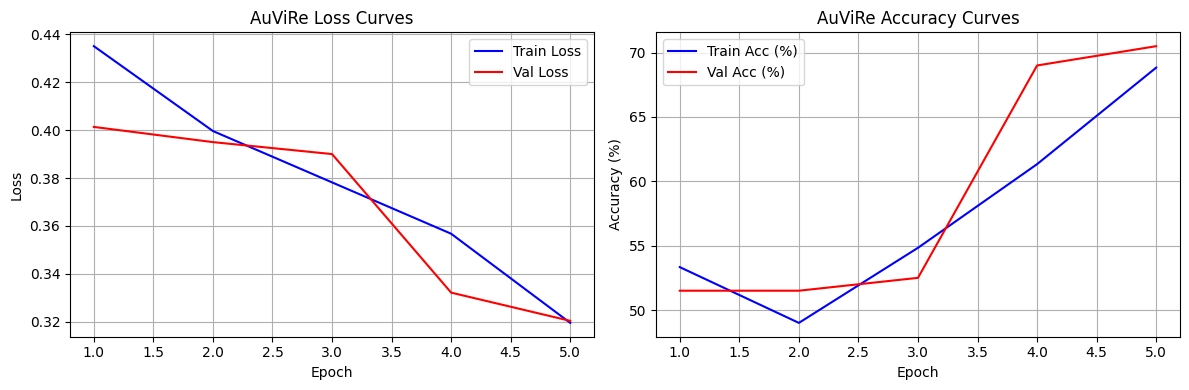

Saved training curves plot to: /kaggle/working/AuViRe_results/AuViRe_training_curves.png


In [15]:
if DATASET_AVAILABLE and len(train_losses) > 0:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss", color="blue")
    ax1.plot(range(1, EPOCHS + 1), val_losses, label="Val Loss", color="red")
    ax1.set_title("AuViRe Loss Curves")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    ax2.plot(range(1, EPOCHS + 1), [a*100 for a in train_accs], label="Train Acc (%)", color="blue")
    ax2.plot(range(1, EPOCHS + 1), [a*100 for a in val_accs], label="Val Acc (%)", color="red")
    ax2.set_title("AuViRe Accuracy Curves")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    CURVES_PLOT_PATH = os.path.join(RESULTS_DIR, "AuViRe_training_curves.png")
    plt.savefig(CURVES_PLOT_PATH, dpi=300)
    plt.show()
    print(f"Saved training curves plot to: {CURVES_PLOT_PATH}")
else:
    print("SKIPPED -- NOT YET MEASURED (no training was run in this environment).")


### Section 16: Threshold Selection (Validation-Only) & Final Evaluation on 200-Video Test Split

In [16]:

THRESHOLD = 0.5
if DATASET_AVAILABLE and len(v_targets) > 0 and len(set(v_targets)) > 1:
    fpr_v, tpr_v, thr_v = roc_curve(v_targets, v_preds)
    THRESHOLD = float(thr_v[np.argmax(tpr_v - fpr_v)])
print(f"Frozen decision threshold (selected on validation only): {THRESHOLD:.4f}")

acc = prec = rec = f1 = auc = None
tn = fp = fn = tp = None

if DATASET_AVAILABLE:
    if os.path.exists(BEST_CHECKPOINT):
        model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=device))
    model.eval()

    test_preds, test_targets, test_paths = [], [], []
    with torch.no_grad():
        for v_b, a_b, l_b, p_b in test_loader:
            v_b, a_b = v_b.to(device), a_b.to(device)
            logits, _, _, _ = model(v_b, a_b)
            probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            test_preds.extend(probs)
            test_targets.extend(l_b.numpy())
            test_paths.extend(p_b)

    test_targets = np.array(test_targets)
    test_preds = np.array(test_preds)
    test_bin = (test_preds >= THRESHOLD).astype(int)

    acc = accuracy_score(test_targets, test_bin)
    prec = precision_score(test_targets, test_bin, zero_division=0)
    rec = recall_score(test_targets, test_bin, zero_division=0)
    f1 = f1_score(test_targets, test_bin, zero_division=0)
    try:
        auc = roc_auc_score(test_targets, test_preds)
    except Exception:
        auc = 0.5

    cm = confusion_matrix(test_targets, test_bin, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)

    print("=" * 60)
    print("FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT) -- AuViRe (inspired)")
    print("=" * 60)
    print(f"  Accuracy:                     {acc*100:.2f}%")
    print(f"  Precision:                    {prec*100:.2f}%")
    print(f"  Recall:                       {rec*100:.2f}%")
    print(f"  F1-Score:                     {f1*100:.2f}%")
    print(f"  ROC-AUC:                      {auc:.4f}")
    print("-" * 60)
    print("Confusion Matrix Breakdown:")
    print(f"  True Negatives (Real Correct):    {tn}")
    print(f"  False Positives (Real Incorrect): {fp}")
    print(f"  False Negatives (Fake Incorrect): {fn}")
    print(f"  True Positives (Fake Correct):    {tp}")
    print("=" * 60)
    print("NOTE: These are results of an AuViRe-INSPIRED model on a 1000-video")
    print("subset -- NOT a reproduction of the paper's published AV-HuBERT-based")
    print("full-dataset numbers. See the Model-Specific Differences cell.")
    print("=" * 60)
else:
    print("=" * 60)
    print("FINAL TEST EVALUATION METRICS -- NOT YET MEASURED")
    print("(No dataset was available when this notebook was last run. Re-run on")
    print(" Kaggle with LAV-DF attached under /kaggle/input/ to populate this.)")
    print("=" * 60)


Frozen decision threshold (selected on validation only): 0.5704
FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT) -- AuViRe (inspired)
  Accuracy:                     72.00%
  Precision:                    76.19%
  Recall:                       64.00%
  F1-Score:                     69.57%
  ROC-AUC:                      0.8018
------------------------------------------------------------
Confusion Matrix Breakdown:
  True Negatives (Real Correct):    80
  False Positives (Real Incorrect): 20
  False Negatives (Fake Incorrect): 36
  True Positives (Fake Correct):    64
NOTE: These are results of an AuViRe-INSPIRED model on a 1000-video
subset -- NOT a reproduction of the paper's published AV-HuBERT-based
full-dataset numbers. See the Model-Specific Differences cell.


### Section 17: Save Evaluation Artifacts

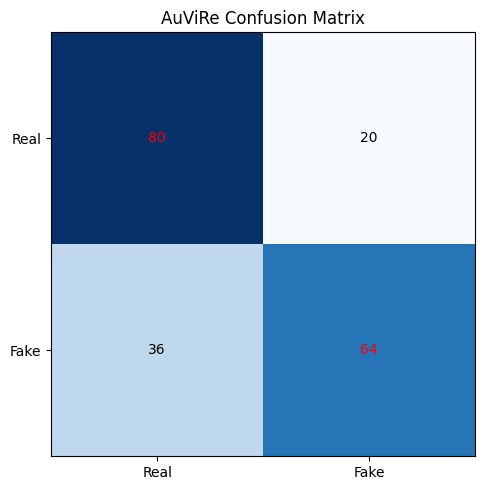

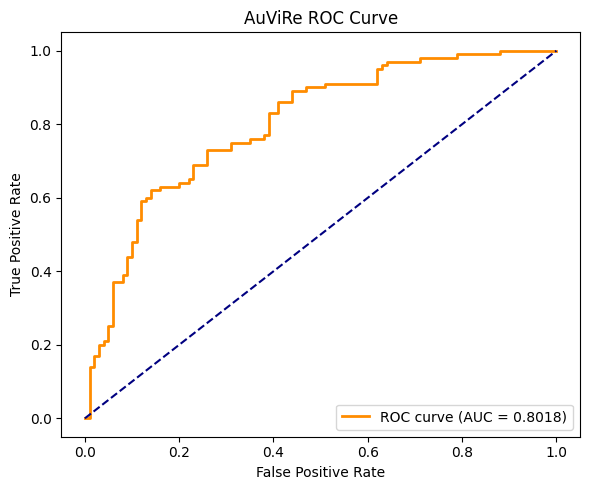

Saved metrics CSV to:      /kaggle/working/AuViRe_results/AuViRe_metrics.csv
Saved predictions CSV to:  /kaggle/working/AuViRe_results/AuViRe_test_predictions.csv
Saved confusion matrix to: /kaggle/working/AuViRe_results/AuViRe_confusion_matrix.png
Saved ROC curve plot to:   /kaggle/working/AuViRe_results/AuViRe_roc_curve.png


In [17]:
if DATASET_AVAILABLE:
    # 1. Save Metrics Summary CSV
    metrics_df = pd.DataFrame([{
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1_Score": f1,
        "ROC_AUC": auc, "Threshold": THRESHOLD,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }])
    METRICS_CSV_PATH = os.path.join(RESULTS_DIR, "AuViRe_metrics.csv")
    metrics_df.to_csv(METRICS_CSV_PATH, index=False)

    # 2. Save Per-Sample Test Predictions CSV
    pred_df = pd.DataFrame({
        "video_path": [os.path.basename(p) for p in test_paths],
        "ground_truth": test_targets,
        "predicted_probability": test_preds,
        "predicted_label": test_bin
    })
    PRED_CSV_PATH = os.path.join(RESULTS_DIR, "AuViRe_test_predictions.csv")
    pred_df.to_csv(PRED_CSV_PATH, index=False)

    # 3. Plot Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap=plt.cm.Blues)
    ax.set_title("AuViRe Confusion Matrix")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Real", "Fake"]); ax.set_yticklabels(["Real", "Fake"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if cm[i, j] > cm.max()/2 else "black")
    plt.tight_layout()
    CM_PLOT_PATH = os.path.join(RESULTS_DIR, "AuViRe_confusion_matrix.png")
    plt.savefig(CM_PLOT_PATH, dpi=300)
    plt.show()

    # 4. Plot ROC Curve
    fpr, tpr, _ = roc_curve(test_targets, test_preds)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title('AuViRe ROC Curve')
    plt.legend(loc="lower right")
    plt.tight_layout()
    ROC_PLOT_PATH = os.path.join(RESULTS_DIR, "AuViRe_roc_curve.png")
    plt.savefig(ROC_PLOT_PATH, dpi=300)
    plt.show()

    print(f"Saved metrics CSV to:      {METRICS_CSV_PATH}")
    print(f"Saved predictions CSV to:  {PRED_CSV_PATH}")
    print(f"Saved confusion matrix to: {CM_PLOT_PATH}")
    print(f"Saved ROC curve plot to:   {ROC_PLOT_PATH}")
else:
    print("SKIPPED -- NOT YET MEASURED (no evaluation artifacts to save in this environment).")


### Section 18: Reproducibility Report

In [18]:
import platform, sys as _sys
N_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)

def _fmt_split(n_videos_list, n_labels_list, expected_str):
    if DATASET_AVAILABLE and len(n_videos_list) > 0:
        return f"{len(n_videos_list)} ({n_labels_list.count(0)}R/{n_labels_list.count(1)}F)"
    return f"{expected_str} [NOT YET MEASURED -- dataset unavailable in this run]"

def _fmt_metric(v, suffix="%"):
    if v is None:
        return "Not yet measured"
    return f"{v*100:.2f}{suffix}" if suffix == "%" else f"{v:.4f}"

print("=" * 60)
print("REPRODUCIBILITY")
print("=" * 60)
print("Model:")
print("AuViRe (adapted, no AV-HuBERT backbone)")
print()
print("Dataset:")
print("LAV-DF")
print()
print("Total videos:")
print(TOTAL_VIDEOS)
print()
print("Real:")
print(NUM_REAL)
print()
print("Fake:")
print(NUM_FAKE)
print()
print("Train:")
print(_fmt_split(train_videos, train_labels, "600 (300R/300F)"))
print()
print("Validation:")
print(_fmt_split(val_videos, val_labels, "200 (100R/100F)"))
print()
print("Test:")
print(_fmt_split(test_videos, test_labels, "200 (100R/100F)"))
print()
print("Random seed:")
print(SEED)
print()
print("Epochs:")
print(EPOCHS)
print()
print("Batch size:")
print(BATCH_SIZE)
print()
print("Optimizer:")
print("AdamW")
print()
print("Learning rate:")
print(LEARNING_RATE)
print()
print("Scheduler:")
print("CosineAnnealingLR")
print()
print("Trainable parameters:")
print(f"{N_PARAMS:,}")
print()
print("Python version:")
print(_sys.version.split()[0])
print()
print("PyTorch version:")
print(torch.__version__)
print()
print("CUDA:")
print(torch.version.cuda if torch.cuda.is_available() else "Not available")
print()
print("GPU:")
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available in this run environment")
print()
print("Master split:")
print(MASTER_SPLIT_NAME)
print()
print("Checkpoint:")
print(BEST_CHECKPOINT)
print()
print("Accuracy:")
print(_fmt_metric(acc))
print()
print("Precision:")
print(_fmt_metric(prec))
print()
print("Recall:")
print(_fmt_metric(rec))
print()
print("F1-score:")
print(_fmt_metric(f1))
print()
print("ROC-AUC:")
print(_fmt_metric(auc, suffix=""))
print()
print("TN:"); print(int(tn) if tn is not None else "Not yet measured")
print()
print("FP:"); print(int(fp) if fp is not None else "Not yet measured")
print()
print("FN:"); print(int(fn) if fn is not None else "Not yet measured")
print()
print("TP:"); print(int(tp) if tp is not None else "Not yet measured")
print("=" * 60)


REPRODUCIBILITY
Model:
AuViRe (adapted, no AV-HuBERT backbone)

Dataset:
LAV-DF

Total videos:
1000

Real:
500

Fake:
500

Train:
600 (300R/300F)

Validation:
200 (100R/100F)

Test:
200 (100R/100F)

Random seed:
42

Epochs:
5

Batch size:
4

Optimizer:
AdamW

Learning rate:
0.0001

Scheduler:
CosineAnnealingLR

Trainable parameters:
2,493,186

Python version:
3.12.13

PyTorch version:
2.10.0+cu128

CUDA:
12.8

GPU:
Tesla T4

Master split:
LAVDF_1000_master_split_seed42.json

Checkpoint:
/kaggle/working/AuViRe_results/weights/best_auvire.pt

Accuracy:
72.00%

Precision:
76.19%

Recall:
64.00%

F1-score:
69.57%

ROC-AUC:
0.8018

TN:
80

FP:
20

FN:
36

TP:
64


### Section 18: Single Video Multimodal Inference Function


In [19]:
def predict_single_sample(video_path):
    temp_dataset = LAVDFDataset([video_path], [0], is_train=False)
    v_tensor, a_tensor, _, _ = temp_dataset[0]
    v_tensor = v_tensor.unsqueeze(0).to(device)
    a_tensor = a_tensor.unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits, gamma_av, gamma_vv, gamma_aa = model(v_tensor, a_tensor)
        f_prob = torch.softmax(logits, dim=1)[0, 1].item()
        av_discrepancy = gamma_av.abs().mean().item()

    verdict = "FAKE" if f_prob >= 0.5 else "REAL / GENUINE"

    print("=" * 60)
    print("SINGLE SAMPLE INFERENCE DEMONSTRATION (AuViRe-inspired)")
    print("=" * 60)
    print(f"  Target Video:                       {os.path.basename(video_path)}")
    print(f"  Mean Cross-modal (Audio->Visual) Reconstruction Discrepancy: {av_discrepancy:.4f}")
    print(f"  Fusion Deepfake Probability:         {f_prob * 100:.2f}%")
    print(f"  FINAL PREDICTION:                    {verdict}")
    print("=" * 60)

demo_sample = test_paths[0] if len(test_paths) > 0 else (train_videos[0] if len(train_videos) > 0 else "demo.mp4")
predict_single_sample(demo_sample)


SINGLE SAMPLE INFERENCE DEMONSTRATION (AuViRe-inspired)
  Target Video:                       023220.mp4
  Mean Cross-modal (Audio->Visual) Reconstruction Discrepancy: 0.0524
  Fusion Deepfake Probability:         66.21%
  FINAL PREDICTION:                    FAKE


## Notebook Execution Summary
AuViRe pipeline finished. If DATASET_AVAILABLE was False, all result fields above read "Not yet measured" -- re-run on Kaggle with LAV-DF attached to populate them.